# 03. CatBoost: прогноз итога продаж по зонам

Модель — `src/model.py`, функция `catboost_predict(train, val, as_of)` по контракту `src.validation.evaluate`.
Сравниваем с baseline (среднее по зоне, RMSE 141.0) и smart baseline (уровень зоны в сезоне, RMSE 135.2)
на тех же 3 фолдах «псевдо-сегодня».

**Как устроена модель**
- Каждый сыгранный матч разворачивается в срезы: состояние продаж за h дней до матча
  (h = 1, 3, …, 40) и срез «продажи ещё не открыты». Так модель учится и на матчах в продаже
  (6 из 17 test-матчей), и на ещё не открытых.
- Признаки среза — только по данным раньше даты среза: уровень зоны в сезоне и за 5 матчей,
  sold_as_of / sold_last_7d / sold_last_14d, доля прошедшего окна продаж, темп относительно типичной
  кривой продаж, соперник (как матчи с ним отклонялись от уровня зоны), день недели, час, месяц,
  сила соперника и форма Авангарда из khl_games.
- Таргет — остаток продаж (итог − уже продано). Две модели: остаток в долях уровня зоны (для матчей,
  которые ещё не в продаже) и в долях свободных мест (для матчей в продаже — учитывает потолок зоны).

In [1]:
import sys
from functools import partial
from pathlib import Path

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.baseline import smart_baseline_predict, zone_mean_predict
from src.model import FEATURES, catboost_predict
from src.validation import evaluate, predict_test

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)

## Валидация: модель против baseline

In [2]:
res = evaluate(catboost_predict)
res_base = evaluate(zone_mean_predict)
res_smart = evaluate(smart_baseline_predict)

by_fold = pd.concat({"catboost": res.by_fold["rmse"], "smart_baseline": res_smart.by_fold["rmse"],
                     "baseline": res_base.by_fold["rmse"]}, axis=1)
by_fold["matches"] = res.by_fold["matches"]
print(f"RMSE catboost = {res.overall:.1f}   smart baseline = {res_smart.overall:.1f}   "
      f"baseline = {res_base.overall:.1f}")
by_fold.round(1)

RMSE catboost = 124.7   smart baseline = 135.2   baseline = 141.0


,catboost,smart_baseline,baseline,matches
fold,,,,
2023-12-15,163.3,172.2,172.2,14
2024-11-25,83.1,79.1,103.0,17
2025-09-20,121.6,148.5,147.2,12
all,124.7,135.2,141.0,43


### По зонам (все фолды)

In [3]:
by_zone = pd.concat({"catboost": res.by_zone["all"], "smart_baseline": res_smart.by_zone["all"],
                     "baseline": res_base.by_zone["all"]}, axis=1)
by_zone["delta_vs_baseline"] = by_zone["catboost"] - by_zone["baseline"]
by_zone.round(1)

,catboost,smart_baseline,baseline,delta_vs_baseline
zone,,,,
1,26.2,36.8,41.6,-15.4
2,26.2,28.9,38.4,-12.2
3,53.1,59.1,63.3,-10.2
4,119.6,139.0,164.3,-44.7
5,117.5,119.5,109.4,8.1
6,202.6,225.7,257.0,-54.4
7,218.8,228.4,208.5,10.4
8,55.5,62.2,58.8,-3.3


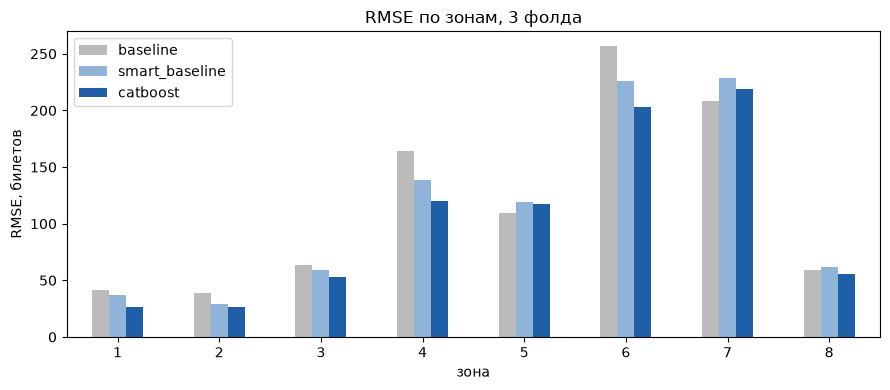

In [4]:
ax = by_zone[["baseline", "smart_baseline", "catboost"]].plot.bar(figsize=(9, 4), rot=0,
                                                                   color=["#bbbbbb", "#8fb3d9", "#1f5fa8"])
ax.set_ylabel("RMSE, билетов"); ax.set_xlabel("зона"); ax.set_title("RMSE по зонам, 3 фолда")
plt.tight_layout()

### Матчи в продаже и ещё не в продаже на дату as_of

In [5]:
pd.concat({"catboost": res.by_status["rmse"], "smart_baseline": res_smart.by_status["rmse"],
           "baseline": res_base.by_status["rmse"], "matches": res.by_status["matches"]}, axis=1).round(1)

,catboost,smart_baseline,baseline,matches
in_sale,,,,
ещё не в продаже,132.0,144.5,149.5,30
в продаже,105.8,110.9,119.3,13


## Абляции: вклад групп признаков

Убираем группу признаков и смотрим, насколько вырастет RMSE (больше — группа полезнее).

In [6]:
GROUPS = {
    "продажи на дату (sold_*, темп, доля окна)": ["sold_as_of", "sold_last_7d", "sold_last_14d", "frac_elapsed",
                                                  "days_left", "pace_est", "sold_lvl", "sold_cap", "match_sold_ratio"],
    "соперник: история в Омске": ["opp_rel", "opp_n"],
    "КХЛ: сила соперника и форма Авангарда": ["opp_winrate", "opp_gd", "avg_winrate", "avg_form10", "avg_gd10"],
    "календарь (день недели, час, месяц)": ["weekday", "hour", "month"],
}
rows = []
for name, cols in GROUPS.items():
    r = evaluate(partial(catboost_predict, features=[f for f in FEATURES if f not in cols]))
    rows.append({"без группы": name, "rmse": r.overall, "рост_rmse": r.overall - res.overall})
pd.DataFrame(rows).set_index("без группы").round(1)

,rmse,рост_rmse
без группы,,
"продажи на дату (sold_*, темп, доля окна)",299.3,174.6
соперник: история в Омске,124.1,-0.5
КХЛ: сила соперника и форма Авангарда,122.5,-2.2
"календарь (день недели, час, месяц)",121.0,-3.7


## Разбор ошибок

In [7]:
p = res.preds.assign(err=lambda d: d["y_pred"] - d["y_true"])
print("Худшие строки (матч × зона):")
display(p.reindex(p["err"].abs().sort_values(ascending=False).index).head(12))

print("Средняя ошибка (прогноз − факт) по зонам: > 0 — переоцениваем")
p.groupby("zone")["err"].agg(["mean", lambda e: np.sqrt((e ** 2).mean())]).set_axis(["bias", "rmse"], axis=1).round(1)

Худшие строки (матч × зона):


,fold,match_id,zone,in_sale,y_true,y_pred,err
78,2023-12-15,M030,7,False,349,863,514
86,2023-12-15,M031,7,False,377,886,509
94,2023-12-15,M032,7,False,441,919,478
70,2023-12-15,M029,7,False,353,824,471
85,2023-12-15,M031,6,False,990,558,-432
93,2023-12-15,M032,6,False,1004,615,-389
37,2023-12-15,M025,6,True,417,802,385
334,2025-09-20,M084,7,False,383,753,370
110,2023-12-15,M034,7,False,465,827,362
29,2023-12-15,M024,6,True,457,814,357


Средняя ошибка (прогноз − факт) по зонам: > 0 — переоцениваем


,bias,rmse
zone,,
1,-3.4,26.2
2,-10.1,26.2
3,17.4,53.1
4,-73.4,119.6
5,-79.1,117.5
6,-32.3,202.6
7,-23.7,218.8
8,-12.7,55.5


Основная ошибка — зоны 6 и 7. Их продажи переключаются «режимами»: на части матчей зона 6 продаёт ~1000
билетов, а зона 7 ~350, на других наоборот (например, M029–M032, M069–M072). До открытия продаж это почти
не предсказуемо по имеющимся данным; когда продажи идут, модель видит режим по sold_as_of — поэтому
ошибка на матчах в продаже заметно ниже.

## Прогноз на test (обучение на всех 85 матчах, as_of = 15.12.2025)

In [8]:
sub = predict_test(catboost_predict)
out = ROOT / "submissions" / "catboost.csv"
sub.to_csv(out, index=False, encoding="utf-8")
print(f"Сохранено: {out.relative_to(ROOT)}, {len(sub)} строк, сумма {sub['tickets_total'].sum()}")
sub.pivot(index="match_id", columns="zone", values="tickets_total")

Сохранено: submissions\catboost.csv, 136 строк, сумма 85631


zone,1,2,3,4,5,6,7,8
match_id,,,,,,,,
M086,450,256,583,889,745,642,777,415
M087,475,266,623,912,811,884,937,440
M088,407,238,514,810,760,753,789,392
M089,472,267,630,882,809,820,851,427
M090,469,287,662,940,870,700,836,467
M091,472,279,651,947,890,652,795,455
M092,482,273,652,826,777,696,810,429
M093,477,267,651,863,792,718,837,436
M094,484,273,660,893,831,760,908,452


## Вывод: новогодние матчи и признак темпа

На 15.12.2025 на M086–M089 (24–30.12) уже продано 46–59% мест, в 1,6–2,1 раза больше, чем у обычного
матча за 9–15 дней до игры. Если досчитать остаток по **обычной** кривой продаж, вышло бы 117–148%
вместимости. Модель даёт 69–77%.

**Признак темпа.** Проверили через `evaluate` на всех фолдах, не теряет ли модель темп. Признак:
продано / типичная доля, проданная к этому дню.

| вариант | RMSE | матчи в продаже | заполняемость M087 / M088 / M089 |
|---|---|---|---|
| финальная модель (`pace_est` по зоне, `match_sold_ratio` по матчу) | **124,7** | 105,8 | 0,77 / 0,73 / 0,75 |
| кривая как в 04_report: медиана по матчам, уже открытым к этому дню | 124,4 | 105,5 | 0,78 / 0,73 / 0,75 |
| без обрезки темпа сверху (сейчас ≤ 3) | 124,6 | 105,7 | 0,77 / 0,73 / 0,75 |
| кривая как в 04_report + темп всего матча | 122,6 | 102,1 | 0,77 / 0,73 / 0,75 |

Разница в пределах шума (±3), прогноз на новогодние матчи не меняется. Модель оставлена без изменений.

**Новогодние матчи прошлых сезонов** (окно 24.12–08.01, таблицы ниже) продаются по своей кривой:
к 9–15 дням до игры у них уже продано 84–95% итога (кроме M055), то есть спрос приходит рано, и потом
продажи почти встают. При этом в 2025/26 к тому же дню продано **меньше**, чем у 4 из 5 прошлых
новогодних матчей (у M086 — меньше, чем у всех пяти). Если досчитать остаток по новогодней кривой (медиана по 5 матчам), итог M087–M089
выйдет 56–63% (у M086 49%), что ниже прогноза модели (73–77%).

**Риск в обе стороны, скорее переоценка.**
- За переоценку: 4 из 5 аналогов (M023–M025, M056) дают итог ниже прогноза модели.
- За недооценку: M055 (28.12.2024) продавался поздно, и по нему итог вышел бы 81–99%. Кроме того,
  сезон 2025/26 заполнен лучше прошлых (в среднем 70% против 63–66%), а прошлые новогодние матчи
  закончили на 66–72%, на уровне сезона или выше.

Прогноз не меняем: модель видела эти матчи в обучении, а 5 аналогов слишком мало для отдельного правила.
Клубу стоит пересчитать прогноз по свежим продажам ближе к датам матчей.

In [9]:
from src.data import build_table, load_daily_sales

tbl = build_table()
daily = load_daily_sales()
m = (tbl.groupby("match_id")
     .agg(дата=("match_date", "first"), соперник=("opponent", "first"), capacity=("capacity", "sum"),
          итог=("tickets_total", "sum"), продано_15_12=("sold_as_of", "sum"),
          дней_до_матча=("days_to_match", "first"), test=("is_test", "first")))
md_ = m["дата"].dt.month * 100 + m["дата"].dt.day
new_year = m[(md_ >= 1224) | (md_ <= 108)]  # новогоднее окно 24.12–08.01
past = new_year[new_year["test"] == 0].copy()


def sold_before(d):
    """Продано по прошлым новогодним матчам раньше, чем за d дней до игры (как sold_as_of)."""
    return daily[daily["days_before"] > d].groupby("match_id")["tickets"].sum().reindex(past.index, fill_value=0)


for d in (11, 15):
    past[f"продано_за_{d}_дн"] = sold_before(d) / past["capacity"]
past["итог_заполн"] = past["итог"] / past["capacity"]
print("Прошлые новогодние матчи: заполняемость мест")
display(past[["дата", "соперник", "продано_за_11_дн", "продано_за_15_дн", "итог_заполн"]]
        .style.format({"дата": "{:%d.%m.%Y}", "продано_за_11_дн": "{:.0%}", "продано_за_15_дн": "{:.0%}",
                       "итог_заполн": "{:.0%}"}))

# 2025/26: продано на 15.12.2025, прогноз модели и итог по новогодней кривой:
# продано / доля итога, проданная к тому же дню у прошлого новогоднего матча (медиана, мин–макс по 5 матчам)
cur = new_year[(new_year["test"] == 1) & (new_year["продано_15_12"] > 0)].copy()
cur["продано"] = cur["продано_15_12"] / cur["capacity"]
cur["прогноз_модели"] = sub.groupby("match_id")["tickets_total"].sum().reindex(cur.index) / cur["capacity"]
for mid, r in cur.iterrows():
    est = r["продано_15_12"] / (sold_before(int(r["дней_до_матча"])) / past["итог"]) / r["capacity"]
    cur.loc[mid, ["по_НГ_кривой", "мин", "макс"]] = est.median(), est.min(), est.max()
print("Новогодние матчи 2025/26: продано на 15.12.2025, прогноз модели и итог по новогодней кривой")
display(cur[["дата", "соперник", "дней_до_матча", "продано", "прогноз_модели", "по_НГ_кривой", "мин", "макс"]]
        .style.format({"дата": "{:%d.%m.%Y}", "продано": "{:.0%}", "прогноз_модели": "{:.0%}",
                       "по_НГ_кривой": "{:.0%}", "мин": "{:.0%}", "макс": "{:.0%}"}))

Прошлые новогодние матчи: заполняемость мест


,дата,соперник,продано_за_11_дн,продано_за_15_дн,итог_заполн
match_id,,,,,
M023,24.12.2023,Металлург Мг,62%,58%,70%
M024,03.01.2024,Салават Юлаев,68%,64%,72%
M025,06.01.2024,Лада,66%,62%,71%
M055,28.12.2024,Лада,48%,39%,70%
M056,30.12.2024,Металлург Мг,62%,60%,66%


Новогодние матчи 2025/26: продано на 15.12.2025, прогноз модели и итог по новогодней кривой


,дата,соперник,дней_до_матча,продано,прогноз_модели,по_НГ_кривой,мин,макс
match_id,,,,,,,,
M086,24.12.2025,Нефтехимик,9,46%,69%,49%,48%,60%
M087,26.12.2025,Металлург Мг,11,59%,77%,63%,62%,85%
M088,28.12.2025,Лада,13,51%,73%,56%,55%,81%
M089,30.12.2025,Барыс,15,56%,75%,63%,61%,99%
